# P16: a cheaper guide for the kiosk

The kiosks run on modest CPUs (the brief). P09 timed the final model at 70 ms per photo on one thread of the computer it ran
on. Two ways to make it cheaper, without going back to the weaker models:

1. **int8 quantization of the final model.** Its weights and activations are stored as 8-bit integers instead of 32-bit
   floats: four times smaller, and integer arithmetic is faster on most CPUs. Post-training static quantization (PyTorch FX):
   the network is first run on 200 training paintings to measure the range of every activation, then converted.
2. **A network designed for phones: MobileNetV3** (Large and Small, pretrained on ImageNet, from torchvision). It uses
   depthwise convolutions, far cheaper than the ResNet's. As for the frozen ResNet-18 of P06: the whole network frozen, a new
   final layer trained on our paintings.

**The rules, fixed before any result** (a scratch run, unsaved, checked the code and the run times):

- **int8** is accepted if its validation accuracy is within 1 point of the final model's (83.3%); if so, it is scored once
  on museum B.
- **MobileNetV3**: 5 seeds, 30 epochs, Adam at 1e-3 (the frozen ResNet-18 settings), saved with `run_experiment`. A MobileNet
  is scored once on museum B if its 5-seed validation mean is within 2 points of the final model (at least 81.3%).
- **Cost:** every network is timed here, with the protocol of P09 (one image at a time, interleaved rounds, median), on one
  thread and on all the threads of this computer, and its size is the size of its saved weights. The milliseconds belong to
  this computer (P09's was another one): compare the ratios between networks.

In [1]:
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.ao.quantization import get_default_qconfig_mapping
from torch.ao.quantization.quantize_fx import convert_fx, prepare_fx

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    RESULTS_DIR, build_cnn, build_dense, build_resnet_head, final_model, load_resnet_data, predict_logits, pretrained_resnet,
    run_experiment, score_on_test, split_images, summary, time_per_image, to_tensor)

ENGINE = "fbgemm" if "fbgemm" in torch.backends.quantized.supported_engines else "qnnpack"
torch.backends.quantized.engine = ENGINE  # fbgemm on x86 processors, qnnpack on ARM ones (this computer: see below)
print("quantized engine:", ENGINE, "| threads available:", torch.get_num_threads())


def size_mb(model):
    """Size of the saved weights, in MB."""
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.tell() / 1e6


fp32 = final_model()
val_images, val_labels = split_images("val")
fp32_val_logits = predict_logits(fp32, val_images)
fp32_val = (fp32_val_logits.argmax(1) == val_labels).float().mean().item()
print(f"final model (float32): validation {fp32_val:.1%}, {size_mb(fp32):.1f} MB")

quantized engine: qnnpack | threads available: 4


final model (float32): validation 83.3%, 44.8 MB


## 1. int8 quantization of the final model

In [2]:
import warnings

train_images, _ = split_images("train")
calibration = [train_images[i] for i in torch.randperm(len(train_images), generator=torch.Generator().manual_seed(0))[:200].tolist()]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # torch.ao.quantization announces its move to the torchao package
    prepared = prepare_fx(copy.deepcopy(fp32), get_default_qconfig_mapping(ENGINE), example_inputs=(to_tensor(calibration[:1]),))
    with torch.no_grad():
        for i in range(0, len(calibration), 50):  # measure the range of every activation on 200 training paintings
            prepared(to_tensor(calibration[i:i + 50]))
    int8 = convert_fx(prepared)

int8_val_logits = predict_logits(int8, val_images)
int8_val = (int8_val_logits.argmax(1) == val_labels).float().mean().item()
agreement = (int8_val_logits.argmax(1) == fp32_val_logits.argmax(1)).float().mean().item()
int8_accepted = int8_val >= fp32_val - 0.01
print(f"int8: validation {int8_val:.1%} (float32 {fp32_val:.1%}); same prediction as float32 on {agreement:.1%} of the paintings; "
      f"{size_mb(int8):.1f} MB against {size_mb(fp32):.1f} MB")
print("rule (within 1 point of float32):", "accepted" if int8_accepted else "rejected")

int8: validation 83.3% (float32 83.3%); same prediction as float32 on 98.1% of the paintings; 11.2 MB against 44.8 MB
rule (within 1 point of float32): accepted


**What we see.**

- **int8 costs nothing measurable in accuracy:** 83.3% on validation, as in float32, and the same predicted genre for 98.1% of the paintings (9 of 480 change, with no net effect on the accuracy). The weights go from 44.8 MB to 11.2 MB. The rule is met: it is scored on museum B in section 4.
- This computer has an ARM processor, so the quantized kernels are those of `qnnpack`; an x86 kiosk would use `fbgemm`. The notebook picks the engine itself.

## 2. MobileNetV3, frozen, with a new final layer

In [3]:
BASE = {"image_size": 224, "finetune": "head", "epochs": 30, "lr": 1e-3, "batch_size": 64, "weight_decay": 0.0, "dropout": 0.0, "seed": 0}
mobilenets = {}
for arch in ["mobilenet_v3_large", "mobilenet_v3_small"]:
    config = {**BASE, "model": arch}
    start = time.time()
    features = load_resnet_data(config)
    print(f"===== {arch}: features {tuple(features['X_train'].shape)} ({time.time() - start:.0f} s)")
    mobilenets[arch] = run_experiment(f"{arch}_head", config, seeds=5, build_model=build_resnet_head, load_fn=lambda c: features)
    accs = mobilenets[arch]["val_acc_by_seed"]
    print(f"===== {arch}: mean {np.mean(accs):.1%} (std {np.std(accs, ddof=1):.1%}, {min(accs):.1%} to {max(accs):.1%})"
          f" -> {'scored on museum B' if np.mean(accs) >= fp32_val - 0.02 else 'not scored on museum B'}\n")

===== mobilenet_v3_large: features (1920, 960) (103 s)
4805 parameters | before training: loss 1.624 (ln 5 = 1.609), accuracy 21.1%
epoch   1 | train loss 0.696 acc 0.807 | val loss 0.757 acc 0.746
epoch   5 | train loss 0.391 acc 0.876 | val loss 0.505 acc 0.808
epoch  10 | train loss 0.307 acc 0.899 | val loss 0.483 acc 0.800
epoch  15 | train loss 0.259 acc 0.919 | val loss 0.487 acc 0.819
epoch  20 | train loss 0.223 acc 0.932 | val loss 0.485 acc 0.810


epoch  25 | train loss 0.202 acc 0.941 | val loss 0.499 acc 0.823
epoch  30 | train loss 0.175 acc 0.957 | val loss 0.501 acc 0.827

best validation accuracy 82.7% at epoch 30 (0 s)
seed 1 (1 of 4 more): training, about 0 s...


   best validation accuracy 83.1% at epoch 15
seed 2 (2 of 4 more): training, about 0 s...


   best validation accuracy 82.7% at epoch 18
seed 3 (3 of 4 more): training, about 0 s...


   best validation accuracy 83.1% at epoch 15
seed 4 (4 of 4 more): training, about 0 s...


...

   best validation accuracy 80.4% at epoch 27
seed 2 (2 of 4 more): training, about 0 s...


   best validation accuracy 80.2% at epoch 14
seed 3 (3 of 4 more): training, about 0 s...


   best validation accuracy 80.2% at epoch 27
seed 4 (4 of 4 more): training, about 0 s...


   best validation accuracy 80.0% at epoch 30


saved results/mobilenet_v3_small_head_2026-10-26_19-13-14.pkl and added a row to results/experiments.csv
===== mobilenet_v3_small: mean 80.2% (std 0.2%, 80.0% to 80.4%) -> not scored on museum B



**What we see.**

- **MobileNetV3-Large, frozen, with a new final layer: 82.9%** (std 0.2, 82.7% to 83.1%), 2.6 points above the frozen ResNet-18 (80.3%, P06) and only 0.4 below the final model, which also trains its last block. Within the 2-point rule: scored on museum B.
- **MobileNetV3-Small: 80.2%** (std 0.2), the level of the frozen ResNet-18. More than 2 points below the final model: not scored on museum B.
- Only 4,805 and 2,885 weights are trained; the frozen features take 103 s and 54 s to compute once.

## 3. What each network costs on this computer

All the networks of the project that could run on a kiosk, re-timed here: the dense baseline and the small CNN (P02, P04),
the final ResNet-18 in float32 and int8, a frozen ResNet-50 (P08) and the two MobileNets. The weights do not change the time,
so the dense network, the CNN and the ResNet-50 are timed with untrained final layers. About 2 minutes per thread setting;
close other programs for a fair measure.

In [4]:
r50 = pretrained_resnet("resnet50")
r50.fc = nn.Linear(2048, 5)
networks = {
    "dense baseline, 32 px": (nn.Sequential(nn.Flatten(), build_dense({"image_size": 32, "hidden": 128})).eval(), 32),
    "small CNN, 64 px": (build_cnn({"conv_channels": [16, 32, 64]}).eval(), 64),
    "final ResNet-18, float32": (fp32, 224),
    "final ResNet-18, int8": (int8, 224),
    "ResNet-50 frozen": (r50.eval(), 224),
}
for arch in ["mobilenet_v3_large", "mobilenet_v3_small"]:
    m = pretrained_resnet(arch)
    networks[f"MobileNetV3-{arch.split('_')[-1].title()} frozen"] = (
        nn.Sequential(m.features, m.avgpool, nn.Flatten(), build_resnet_head({"model": arch})).eval(), 224)

ALL = torch.get_num_threads()
one = time_per_image(networks, threads=1)
many = time_per_image(networks, threads=ALL)
cost = pd.DataFrame({"1 thread (ms)": one.median(), "1 thread, range": one.min().round(1).astype(str) + " to " + one.max().round(1).astype(str),
                     f"{ALL} threads (ms)": many.median(),
                     "size (MB)": {label: size_mb(net) for label, (net, _) in networks.items()},
                     "weights (millions)": {label: sum(p.numel() for p in net.parameters()) / 1e6 for label, (net, _) in networks.items()}})
cost.loc["final ResNet-18, int8", "weights (millions)"] = cost.loc["final ResNet-18, float32", "weights (millions)"]  # stored as int8, not as parameters
cost["1 thread, relative to final float32"] = cost["1 thread (ms)"] / cost.loc["final ResNet-18, float32", "1 thread (ms)"]
cost.round(2)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /Users/yonimahieddine/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


,1 thread (ms),"1 thread, range",4 threads (ms),size (MB),weights (millions),"1 thread, relative to final float32"
"dense baseline, 32 px",0.02,0.0 to 0.0,0.02,1.58,0.39,0.00
"small CNN, 64 px",0.41,0.4 to 0.4,0.31,0.10,0.02,0.03
"final ResNet-18, float32",16.56,16.1 to 18.8,10.97,44.79,11.18,1.00
"final ResNet-18, int8",12.26,12.2 to 12.9,13.19,11.22,11.18,0.74
ResNet-50 frozen,27.11,26.9 to 49.5,21.16,94.39,23.52,1.64
MobileNetV3-Large frozen,19.14,19.0 to 19.6,44.41,12.10,2.98,1.16
MobileNetV3-Small frozen,11.16,11.0 to 12.1,32.26,3.85,0.93,0.67


**What we see.**

- **This computer is about four times faster than P09's:** the final ResNet-18 takes 16.6 ms on one thread here, 70 ms there. The ratios agree: the small CNN costs 2.5% of the ResNet-18 here and 2.4% in P09; the ResNet-50 costs 1.6 times the ResNet-18 here, 2.0 times in P09.
- **int8 is 26% faster on one thread** (12.3 against 16.6 ms) and 4 times smaller. On 4 threads it is slower than float32 (13.2 against 11.0 ms): the quantized kernels barely use the extra threads on this processor.
- **MobileNetV3 is not faster here, despite about 8 times fewer operations** (0.22 against 1.8 billion per image, published figures): the Large one takes 19.1 ms on one thread (1.16 times the ResNet-18), the Small one 11.2 ms. On 4 threads both are 2.3 and 2.9 times *slower* than on one (44 and 32 ms). The depthwise convolutions they are built from are much less optimised in PyTorch on this CPU than the ResNet's ordinary ones. The number of operations does not predict the time: it has to be measured on the kiosk's own processor.
- Sizes: MobileNetV3-Large 12.1 MB and Small 3.8 MB, against 44.8 MB for the ResNet-18 in float32 and 11.2 MB in int8.

## 4. Museum B, once, for the networks the rules accept

In [5]:
test_images, test_labels = split_images("test")
rows = summary()
museum_b = {"final ResNet-18, float32": rows[rows["name"] == "resnet18_layer4"].sort_values("date")["test_acc"].iloc[0]}
fp32_test = (predict_logits(fp32, test_images).argmax(1) == test_labels).float().mean().item()
print(f"final model, float32, recomputed here: {fp32_test:.1%} (recorded {museum_b['final ResNet-18, float32']:.1%})")
if int8_accepted:
    museum_b["final ResNet-18, int8"] = (predict_logits(int8, test_images).argmax(1) == test_labels).float().mean().item()
for arch, run in mobilenets.items():
    if np.mean(run["val_acc_by_seed"]) >= fp32_val - 0.02:
        row = rows.set_index("file").loc[run["stem"]]
        _, acc = score_on_test(run["stem"]) if pd.isna(row["test_acc"]) else (row["test_loss"], row["test_acc"])
        museum_b[f"MobileNetV3-{arch.split('_')[-1].title()} frozen"] = acc

validation = {"final ResNet-18, float32": fp32_val, "final ResNet-18, int8": int8_val,
              **{f"MobileNetV3-{a.split('_')[-1].title()} frozen": np.mean(r["val_acc_by_seed"]) for a, r in mobilenets.items()}}
kiosk = cost.copy()
kiosk.insert(0, "validation", pd.Series(validation))
kiosk.insert(1, "museum B", pd.Series(museum_b))
kiosk.drop(columns=["1 thread, range"]).to_csv(RESULTS_DIR / "kiosk_cost.csv")
print("written: results/kiosk_cost.csv (validation and museum B only for the networks of this notebook)")
kiosk.drop(columns=["1 thread, range"]).round(3)

final model, float32, recomputed here: 86.0% (recorded 86.0%)


mobilenet_v3_large_head_2026-10-26_19-12-19: test accuracy 84.8%, test loss 0.390 (written in results/experiments.csv)
written: results/kiosk_cost.csv (validation and museum B only for the networks of this notebook)


,validation,museum B,1 thread (ms),4 threads (ms),size (MB),weights (millions),"1 thread, relative to final float32"
"dense baseline, 32 px",NaN,NaN,0.019,0.022,1.578,0.394,0.001
"small CNN, 64 px",NaN,NaN,0.414,0.312,0.099,0.024,0.025
"final ResNet-18, float32",0.833,0.860,16.561,10.971,44.792,11.179,1.000
"final ResNet-18, int8",0.833,0.862,12.263,13.194,11.221,11.179,0.740
ResNet-50 frozen,NaN,NaN,27.113,21.156,94.386,23.518,1.637
MobileNetV3-Large frozen,0.829,0.848,19.140,44.410,12.103,2.977,1.156
MobileNetV3-Small frozen,0.802,NaN,11.165,32.262,3.846,0.930,0.674


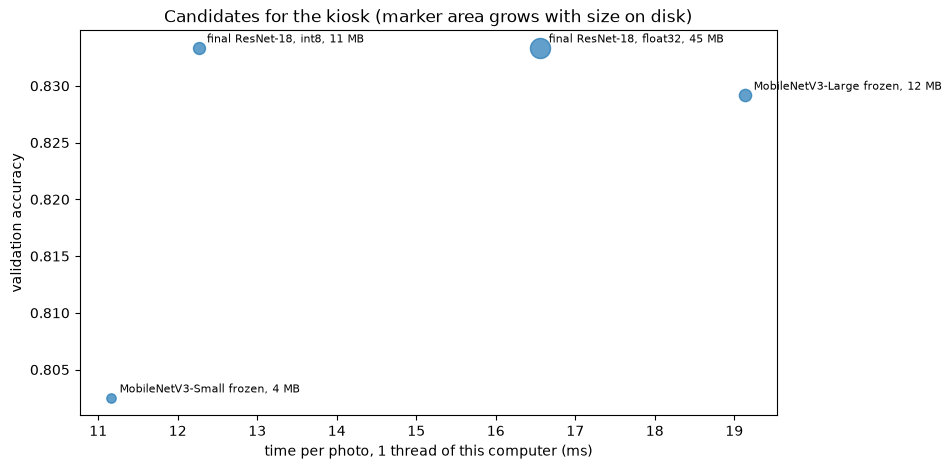

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for label, row in kiosk.dropna(subset=["validation"]).iterrows():
    ax.scatter(row["1 thread (ms)"], row["validation"], s=30 + 4 * row["size (MB)"], color="tab:blue", alpha=0.7)
    ax.annotate(f"{label}, {row['size (MB)']:.0f} MB", (row["1 thread (ms)"], row["validation"]), textcoords="offset points",
                xytext=(6, 4), fontsize=8)
ax.set_xlabel("time per photo, 1 thread of this computer (ms)")
ax.set_ylabel("validation accuracy")
ax.set_title("Candidates for the kiosk (marker area grows with size on disk)")
plt.show()

**What we see.**

- **int8 on museum B: 86.2%**, against 86.0% for float32 (1 painting more right): the quantized model is as good on unseen artists.
- **MobileNetV3-Large on museum B: 84.8%** (loss 0.390), 1.2 points below the final model: inside the noise, and like every model it scores higher on museum B than on validation.
- The float32 model recomputed here gives the recorded 86.0%, so the scores of this notebook are comparable with ADR 0012.

## Saved here

Two rows in `results/experiments.csv` (`mobilenet_v3_large_head`, `mobilenet_v3_small_head`, 5 seeds each) and
`results/kiosk_cost.csv` (time, size, validation and museum B of the kiosk candidates). The int8 model is rebuilt by this
notebook (seeded calibration); it is not saved.

## What we see

| kiosk candidate | validation | museum B | 1 thread, this computer | size |
|---|---|---|---|---|
| final ResNet-18, float32 (ADR 0012) | 83.3% | 86.0% | 16.6 ms | 44.8 MB |
| **final ResNet-18, int8** | **83.3%** | **86.2%** | **12.3 ms** | **11.2 MB** |
| MobileNetV3-Large, frozen | 82.9% | 84.8% | 19.1 ms | 12.1 MB |
| MobileNetV3-Small, frozen | 80.2% | not scored | 11.2 ms | 3.8 MB |

- **For the kiosk, quantize the final model.** Same accuracy on both sets, 4 times smaller, 26% faster on one thread, no retraining: one PyTorch conversion and 200 training paintings to calibrate it.
- **A network built for phones is not automatically cheaper on a CPU.** MobileNetV3-Large matches the final model within the noise and is as small as the int8 ResNet, but it is slower here, and much slower on several threads. It would be the choice only if the kiosk's own processor runs depthwise convolutions well, which has to be measured there.
- **Do not count on extra threads:** on this processor 4 threads speed the float32 ResNet up only 1.5 times and slow the int8 and MobileNet models down; measure on the kiosk before relying on them.

**Limits.** One computer (ARM, macOS), batch of one, no other program running: a kiosk will differ, and only the ratios should be carried over. int8 was calibrated once (200 paintings, seed 0); MobileNets were only tried frozen.